# GOAT vs. Baby GOAT — Descriptive Analysis

**Research scope:** Tom Brady and Patrick Mahomes, first **131 regular-season NFL starts** per quarterback (262 starts total).  
**Status:** Descriptive results only — **not** adjusted for era, roster quality, or strength of opponents.

## Research questions
1. How did the two quarterbacks accumulate their first 100 wins?
2. How do their observed passing rates and production differ over the same number of starts?
3. How do their rushing contributions, scrambles, and sacks compare?

**Important:** Team wins are not an isolated quarterback skill measure. Rushing scrambles are already included in rushing attempts and yards. Sacks are not official rushing attempts. No causal conclusions are warranted from these figures.

**Prerequisite:** Run `python3 scripts/build_complete_qb_stats.py` from the project root.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

# Works when launched from either the project root or the notebooks directory.
ROOT = Path.cwd()
if not (ROOT / "data" / "processed" / "qb_complete_stats.parquet").is_file():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "processed" / "qb_complete_stats.parquet"
FIGURE_DIR = ROOT / "reports" / "figures"
SUMMARY_DIR = ROOT / "reports"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Missing {DATA_PATH}. Run python3 scripts/build_complete_qb_stats.py first."
    )

df = pl.read_parquet(DATA_PATH).sort(["player_name", "start_no"])
print(f"Loaded {df.height} starts across {df['player_name'].n_unique()} QBs.")


Loaded 262 starts across 2 QBs.


## 1. Sample validation

Check the sample **before** looking at results. Changes to row counts or start numbering invalidate the comparisons. Results are not independently reverified by this notebook; it relies on the audited upstream datasets.


In [2]:
assert df.height == 262, "Expected 262 starts."
assert df.select(pl.struct("player_id", "game_id").n_unique()).item() == 262

for name, games in df.group_by("player_name"):
    assert games.height == 131
    assert sorted(games["start_no"].to_list()) == list(range(1, 132))
    wins = games.filter(pl.col("result") == "W").height
    losses = games.filter(pl.col("result") == "L").height
    assert (wins, losses) == (100, 31)

print("PASS: 262 unique starts, 131 per quarterback, both records 100-31.")


PASS: 262 unique starts, 131 per quarterback, both records 100-31.


## 2. Aggregate statistics

All rates are computed using **sums over the 131 starts**. Do not average game-level percentages: a game with 5 attempts should not have the same weight as one with 45 attempts.

- Passing rates use **official-style pass attempts** as their denominators.
- `yards_per_carry` includes kneel-downs; `yards_per_non_kneel_carry` is also shown for mobility discussion.
- `scrambles` are a **subset** of rushing attempts, not an additional category to sum into total carries.


In [3]:
COUNTS = [
    "attempts", "completions", "passing_yards", "passing_tds", "interceptions",
    "carries", "rushing_yards", "rushing_tds", "scrambles", "scramble_yards",
    "designed_runs", "designed_run_yards", "kneels", "kneel_yards",
    "non_kneel_carries", "non_kneel_yards", "sacks_taken", "sack_yards_lost",
]

summary = (
    df.group_by("player_name")
    .agg(*[pl.col(c).sum().alias(c) for c in COUNTS], pl.len().alias("starts"))
    .with_columns(
        (100 * pl.col("completions") / pl.col("attempts")).alias("completion_pct"),
        (pl.col("passing_yards") / pl.col("attempts")).alias("yards_per_attempt"),
        (100 * pl.col("passing_tds") / pl.col("attempts")).alias("td_rate"),
        (100 * pl.col("interceptions") / pl.col("attempts")).alias("int_rate"),
        (pl.col("rushing_yards") / pl.col("carries")).alias("yards_per_carry"),
        (pl.col("non_kneel_yards") / pl.col("non_kneel_carries")).alias("yards_per_non_kneel_carry"),
        (100 * pl.col("scrambles") / pl.col("non_kneel_carries")).alias("scramble_share_non_kneel_pct"),
        (pl.col("sacks_taken") / pl.col("starts")).alias("sacks_per_start"),
    )
    .sort("player_name")
)

summary.write_csv(SUMMARY_DIR / "descriptive_summary.csv")
print(summary.select(
    "player_name", "attempts", "completions", "passing_yards", "passing_tds",
    "interceptions", "carries", "rushing_yards", "rushing_tds", "sacks_taken"
))
print(summary.select(
    "player_name", "completion_pct", "yards_per_attempt", "td_rate", "int_rate",
    "yards_per_carry", "yards_per_non_kneel_carry"
))


shape: (2, 10)
┌────────────┬──────────┬────────────┬───────────┬───┬─────────┬───────────┬───────────┬───────────┐
│ player_nam ┆ attempts ┆ completion ┆ passing_y ┆ … ┆ carries ┆ rushing_y ┆ rushing_t ┆ sacks_tak │
│ e          ┆ ---      ┆ s          ┆ ards      ┆   ┆ ---     ┆ ards      ┆ ds        ┆ en        │
│ ---        ┆ i64      ┆ ---        ┆ ---       ┆   ┆ i64     ┆ ---       ┆ ---       ┆ ---       │
│ str        ┆          ┆ i64        ┆ i64       ┆   ┆         ┆ i64       ┆ i64       ┆ i64       │
╞════════════╪══════════╪════════════╪═══════════╪═══╪═════════╪═══════════╪═══════════╪═══════════╡
│ Patrick    ┆ 4831     ┆ 3198       ┆ 37248     ┆ … ┆ 513     ┆ 2722      ┆ 20        ┆ 224       │
│ Mahomes    ┆          ┆            ┆           ┆   ┆         ┆           ┆           ┆           │
│ Tom Brady  ┆ 4329     ┆ 2752       ┆ 31705     ┆ … ┆ 313     ┆ 580       ┆ 6         ┆ 224       │
└────────────┴──────────┴────────────┴───────────┴───┴─────────┴───────────┴

## 3. Figure 1 — The Road to 100 Wins

**Question:** Did both quarterbacks follow similar cumulative win trajectories?  
**X-axis:** Regular-season start number, 1–131.  
**Y-axis:** Cumulative team wins in games started by the quarterback.


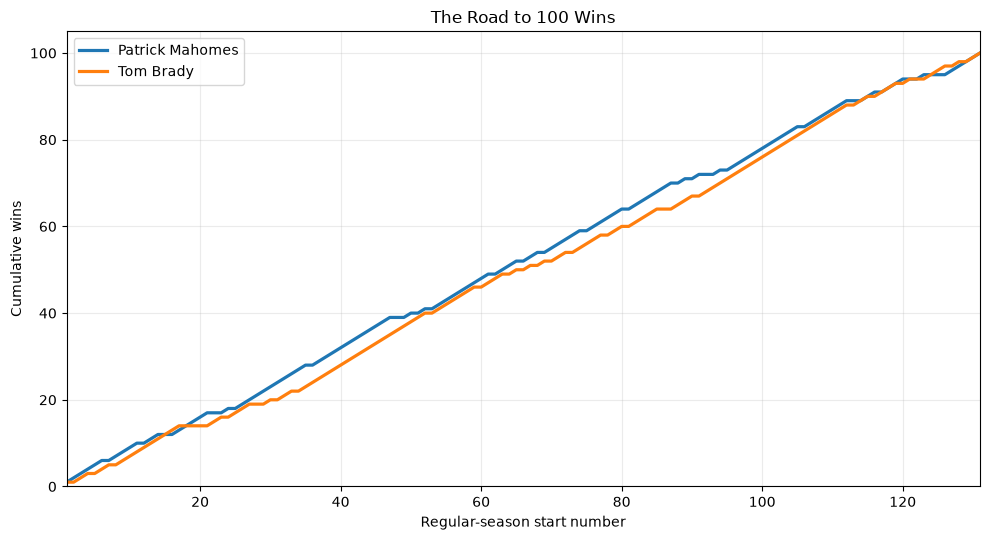

In [4]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for name, player_games in df.group_by("player_name"):
    player_games = player_games.sort("start_no")
    ax.plot(
        player_games["start_no"].to_list(),
        player_games["cumulative_wins"].to_list(),
        linewidth=2.3,
        label=name[0] if isinstance(name, tuple) else name,
    )

ax.set(title="The Road to 100 Wins", xlabel="Regular-season start number", ylabel="Cumulative wins")
ax.set_xlim(1, 131)
ax.set_ylim(0, 105)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "01_road_to_100_wins.png", dpi=200)
plt.show()


**Interpretation notes (fill in after running):**
- Where do the two curves diverge most, if at all?
- Do the differences cluster in particular career segments?
- **Caution:** the y-axis is a team outcome, not a QB-only statistic.


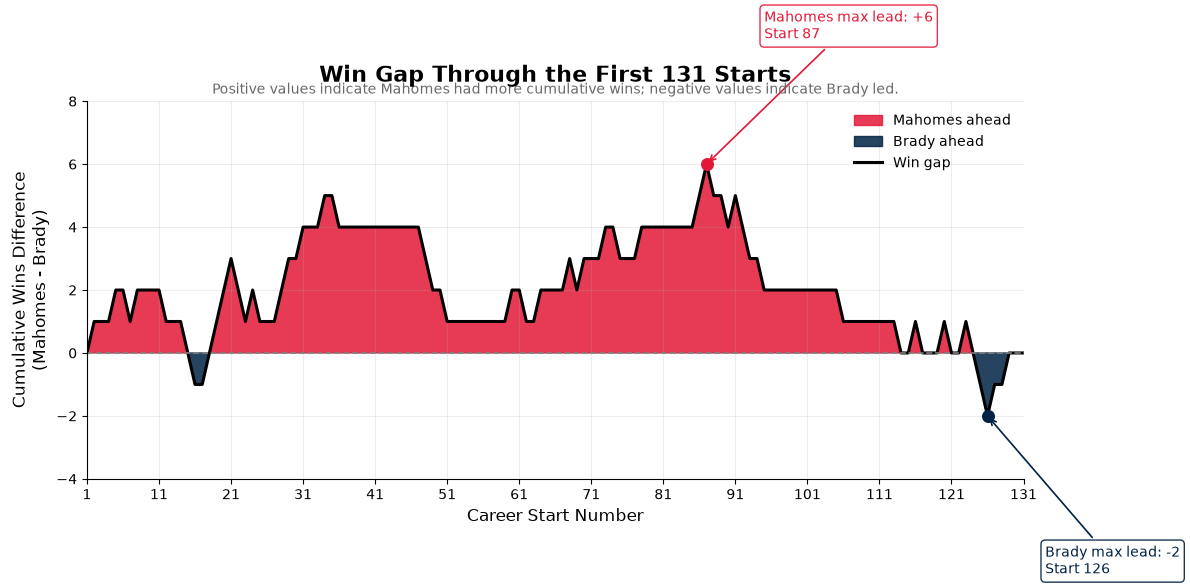

In [11]:
import polars as pl
import matplotlib.pyplot as plt
import numpy as np

# Team colors
PATRIOTS_BLUE = "#002244"
CHIEFS_RED = "#E31837"

# Prepare data
brady_wins = (
    df.filter(pl.col("player_name") == "Tom Brady")
    .select(
        "start_no",
        pl.col("cumulative_wins").alias("brady_wins"),
    )
)

mahomes_wins = (
    df.filter(pl.col("player_name") == "Patrick Mahomes")
    .select(
        "start_no",
        pl.col("cumulative_wins").alias("mahomes_wins"),
    )
)

comparison = (
    brady_wins.join(mahomes_wins, on="start_no")
    .with_columns(
        (pl.col("mahomes_wins") - pl.col("brady_wins")).alias("win_gap")
    )
    .sort("start_no")
)

assert comparison.height == 131

starts = comparison["start_no"].to_numpy()
gap = comparison["win_gap"].to_numpy()

# Find max lead points
max_mahomes_row = comparison.sort("win_gap", descending=True).row(0, named=True)
max_brady_row = comparison.sort("win_gap").row(0, named=True)

max_mahomes_start = max_mahomes_row["start_no"]
max_mahomes_gap = max_mahomes_row["win_gap"]

max_brady_start = max_brady_row["start_no"]
max_brady_gap = max_brady_row["win_gap"]

# Create figure
fig, ax = plt.subplots(figsize=(12, 6.5))

# Fill areas
ax.fill_between(
    starts, 0, gap,
    where=(gap > 0),
    interpolate=True,
    alpha=0.85,
    color=CHIEFS_RED,
    label="Mahomes ahead"
)

ax.fill_between(
    starts, 0, gap,
    where=(gap < 0),
    interpolate=True,
    alpha=0.85,
    color=PATRIOTS_BLUE,
    label="Brady ahead"
)

# Main line
ax.plot(
    starts,
    gap,
    color="black",
    linewidth=2.2,
    label="Win gap"
)

# Zero line
ax.axhline(0, color="gray", linestyle="--", linewidth=1.2)

# Mark largest leads
ax.scatter(
    [max_mahomes_start],
    [max_mahomes_gap],
    color=CHIEFS_RED,
    s=70,
    zorder=5
)

ax.scatter(
    [max_brady_start],
    [max_brady_gap],
    color=PATRIOTS_BLUE,
    s=70,
    zorder=5
)

# Annotate largest leads
ax.annotate(
    f"Mahomes max lead: +{max_mahomes_gap}\nStart {max_mahomes_start}",
    xy=(max_mahomes_start, max_mahomes_gap),
    xytext=(max_mahomes_start + 8, max_mahomes_gap + 4),
    arrowprops=dict(arrowstyle="->", color=CHIEFS_RED, lw=1.2),
    fontsize=10,
    color=CHIEFS_RED,
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=CHIEFS_RED, alpha=0.9)
)

ax.annotate(
    f"Brady max lead: {max_brady_gap}\nStart {max_brady_start}",
    xy=(max_brady_start, max_brady_gap),
    xytext=(max_brady_start + 8, max_brady_gap - 5),
    arrowprops=dict(arrowstyle="->", color=PATRIOTS_BLUE, lw=1.2),
    fontsize=10,
    color=PATRIOTS_BLUE,
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=PATRIOTS_BLUE, alpha=0.9)
)

# Formatting
ax.set_title(
    "Win Gap Through the First 131 Starts",
    fontsize=16,
    fontweight="bold",
    pad=14
)

ax.text(
    0.5, 1.02,
    "Positive values indicate Mahomes had more cumulative wins; negative values indicate Brady led.",
    transform=ax.transAxes,
    ha="center",
    fontsize=10,
    color="dimgray"
)

ax.set_xlabel("Career Start Number", fontsize=12)
ax.set_ylabel("Cumulative Wins Difference\n(Mahomes - Brady)", fontsize=12)

ax.set_xlim(1, 131)
ax.set_xticks(np.arange(1, 132, 10))

# Dynamic y-axis padding
ymin = gap.min()
ymax = gap.max()
padding = 2
ax.set_ylim(ymin - padding, ymax + padding)

ax.grid(alpha=0.22, linewidth=0.8)
ax.legend(frameon=False, loc="upper right")

# Remove top/right spines for cleaner look
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "../reports/figures/01b_win_gap_by_start.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpreting the Win Gap

This figure shows the cumulative win difference between Patrick Mahomes and Tom Brady across their first 131 regular-season starts.

Positive values indicate stretches in which Mahomes had accumulated more wins than Brady at the same point in their careers, while negative values indicate periods in which Brady was ahead.

Although both quarterbacks ultimately reached the same 100–31 record by start 131, the chart helps identify when one player held the stronger pace and whether those differences were sustained or temporary.

## 4. Figure 2 — Passing Production

These are **raw per-attempt rates** from the first 131 starts. They have not been adjusted for NFL era, supporting casts, or defenses faced. Lower interception rate is generally preferable; the interpretation of all four metrics depends on context.


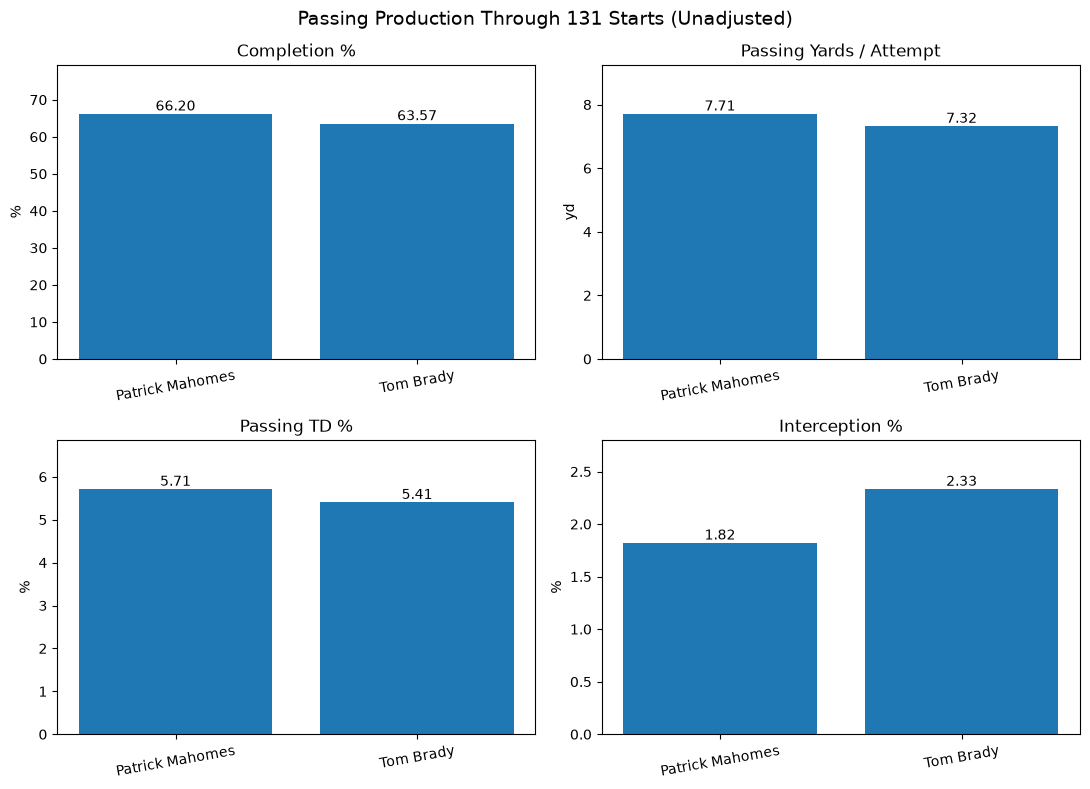

In [5]:
rows = summary.to_dicts()
names = [r["player_name"] for r in rows]
metrics = [
    ("completion_pct", "Completion %", "%"),
    ("yards_per_attempt", "Passing Yards / Attempt", "yd"),
    ("td_rate", "Passing TD %", "%"),
    ("int_rate", "Interception %", "%"),
]

fig, axs = plt.subplots(2, 2, figsize=(11, 8))
for ax, (key, title, unit) in zip(axs.flat, metrics):
    values = [r[key] for r in rows]
    bars = ax.bar(names, values)
    ax.set_title(title)
    ax.set_ylabel(unit)
    ax.set_ylim(0, max(values) * 1.2 if max(values) > 0 else 1)
    ax.tick_params(axis="x", labelrotation=10)
    for bar, value in zip(bars, values):
        ax.annotate(f"{value:.2f}", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    ha="center", va="bottom", fontsize=10)
fig.suptitle("Passing Production Through 131 Starts (Unadjusted)", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "02_passing_production.png", dpi=200)
plt.show()


**Interpretation notes (fill in after running):**
- Which observed differences are large in absolute terms, and which are small?
- Are the measures in tension (e.g., TD rate versus interception rate)?
- **Caution:** differences between NFL eras can materially affect these values.


## 5. Figure 3 — Rushing & Mobility

To prevent double counting, compare carries, scrambles and sacks as **distinct lenses**, not as components to add together. A scramble is already counted within rushing carries. Sacks are separate from official rushing attempts. `scrambles / non-kneel carries` describes the share of rushes attributable to scrambles, **not** the scramble rate per dropback.


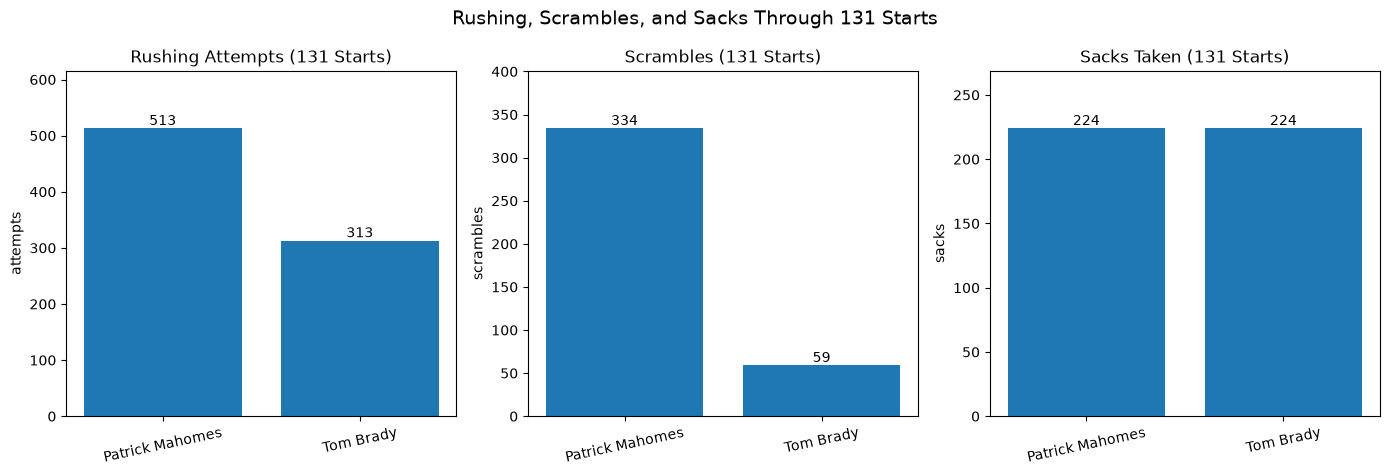

shape: (2, 7)
┌──────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┐
│ player_name  ┆ rushing_yar ┆ rushing_tds ┆ non_kneel_c ┆ yards_per_n ┆ scramble_ya ┆ scramble_sh │
│ ---          ┆ ds          ┆ ---         ┆ arries      ┆ on_kneel_ca ┆ rds         ┆ are_non_kne │
│ str          ┆ ---         ┆ i64         ┆ ---         ┆ rry         ┆ ---         ┆ el_pct      │
│              ┆ i64         ┆             ┆ i64         ┆ ---         ┆ i64         ┆ ---         │
│              ┆             ┆             ┆             ┆ f64         ┆             ┆ f64         │
╞══════════════╪═════════════╪═════════════╪═════════════╪═════════════╪═════════════╪═════════════╡
│ Patrick      ┆ 2722        ┆ 20          ┆ 395         ┆ 7.235443    ┆ 2692        ┆ 84.556962   │
│ Mahomes      ┆             ┆             ┆             ┆             ┆             ┆             │
│ Tom Brady    ┆ 580         ┆ 6           ┆ 187         ┆ 3.764706    ┆ 385 

In [6]:
mobility = [
    ("carries", "Rushing Attempts (131 Starts)", "attempts"),
    ("scrambles", "Scrambles (131 Starts)", "scrambles"),
    ("sacks_taken", "Sacks Taken (131 Starts)", "sacks"),
]

fig, axs = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, (key, title, unit) in zip(axs, mobility):
    values = [r[key] for r in rows]
    bars = ax.bar(names, values)
    ax.set_title(title)
    ax.set_ylabel(unit)
    ax.set_ylim(0, max(values) * 1.2 if max(values) > 0 else 1)
    ax.tick_params(axis="x", labelrotation=12)
    for bar, value in zip(bars, values):
        ax.annotate(f"{value:,}", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    ha="center", va="bottom", fontsize=10)
fig.suptitle("Rushing, Scrambles, and Sacks Through 131 Starts", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "03_rushing_mobility.png", dpi=200)
plt.show()

print(summary.select(
    "player_name", "rushing_yards", "rushing_tds", "non_kneel_carries",
    "yards_per_non_kneel_carry", "scramble_yards", "scramble_share_non_kneel_pct"
))


**Interpretation notes (fill in after running):**
- How much of each player's rushing volume came from scrambles?
- How sensitive is rushing efficiency to kneel-downs?
- **Caution:** sacks depend on offensive line, coverage, time to throw, QB decisions, and other factors; do not treat sacks as a direct measure of QB mobility.


In [7]:

import polars as pl

df = pl.read_parquet("../data/processed/qb_complete_stats.parquet")

# Maximum difference in cumulative wins
brady = (
    df.filter(pl.col("player_name") == "Tom Brady")
    .select(
        "start_no",
        pl.col("cumulative_wins").alias("brady_wins"),
    )
)

mahomes = (
    df.filter(pl.col("player_name") == "Patrick Mahomes")
    .select(
        "start_no",
        pl.col("cumulative_wins").alias("mahomes_wins"),
    )
)

win_comparison = (
    brady.join(mahomes, on="start_no")
    .with_columns(
        (pl.col("mahomes_wins") - pl.col("brady_wins"))
        .alias("win_gap")
    )
    .with_columns(
        pl.col("win_gap").abs().alias("absolute_gap")
    )
    .sort("absolute_gap", descending=True)
)

print("Largest cumulative win differences:")
print(win_comparison.head(10))

# Rushing composition and kneel-down sensitivity
rushing_summary = (
    df.group_by("player_name")
    .agg(
        pl.col("carries").sum(),
        pl.col("rushing_yards").sum(),
        pl.col("scrambles").sum(),
        pl.col("kneels").sum(),
        pl.col("kneel_yards").sum(),
    )
    .with_columns(
        (
            100 * pl.col("scrambles") / pl.col("carries")
        ).alias("scramble_share_pct"),
        (
            pl.col("rushing_yards") / pl.col("carries")
        ).alias("official_ypc"),
        (
            (pl.col("rushing_yards") - pl.col("kneel_yards"))
            / (pl.col("carries") - pl.col("kneels"))
        ).alias("non_kneel_ypc"),
    )
    .with_columns(
        (
            pl.col("non_kneel_ypc") - pl.col("official_ypc")
        ).alias("kneel_ypc_effect")
    )
)

print("\nRushing composition and kneel-down effects:")
print(rushing_summary)


Largest cumulative win differences:
shape: (10, 5)
┌──────────┬────────────┬──────────────┬─────────┬──────────────┐
│ start_no ┆ brady_wins ┆ mahomes_wins ┆ win_gap ┆ absolute_gap │
│ ---      ┆ ---        ┆ ---          ┆ ---     ┆ ---          │
│ u32      ┆ i64        ┆ i64          ┆ i64     ┆ i64          │
╞══════════╪════════════╪══════════════╪═════════╪══════════════╡
│ 87       ┆ 64         ┆ 70           ┆ 6       ┆ 6            │
│ 34       ┆ 22         ┆ 27           ┆ 5       ┆ 5            │
│ 35       ┆ 23         ┆ 28           ┆ 5       ┆ 5            │
│ 86       ┆ 64         ┆ 69           ┆ 5       ┆ 5            │
│ 88       ┆ 65         ┆ 70           ┆ 5       ┆ 5            │
│ 89       ┆ 66         ┆ 71           ┆ 5       ┆ 5            │
│ 91       ┆ 67         ┆ 72           ┆ 5       ┆ 5            │
│ 31       ┆ 20         ┆ 24           ┆ 4       ┆ 4            │
│ 32       ┆ 21         ┆ 25           ┆ 4       ┆ 4            │
│ 33       ┆ 22         ┆

### Rushing & Mobility — Key Findings

**Rushing Volume and Scramble Usage**

Patrick Mahomes accumulated 513 rushing attempts and 2,722 rushing yards across his first 131 starts, compared with 313 attempts and 580 yards for Tom Brady.

Scrambles accounted for 65.1% of Mahomes's rushing attempts, compared with 18.8% for Brady. This suggests substantially different rushing profiles: Mahomes relied more heavily on runs originating from passing plays, while a larger proportion of Brady's attempts came from other rushing situations.

These percentages describe the composition of rushing attempts, not the frequency of scrambling per dropback.

**The Effect of Kneel-Downs**

Kneel-downs had a substantial influence on both quarterbacks' official rushing efficiency.

- Mahomes: 5.31 official yards per carry versus 7.24 excluding kneels.
- Brady: 1.85 official yards per carry versus 3.76 excluding kneels.

The absolute effect was similar, approximately 1.9 yards per carry for both quarterbacks. However, the relative effect was considerably larger for Brady.

This demonstrates why kneel-downs should be separated from conventional rushing attempts when evaluating quarterback mobility and rushing efficiency.

**Limitations and Next Steps**

These findings describe rushing production and usage but do not establish the overall value of each quarterback's rushing contribution.

A subsequent analysis should consider rushing EPA, scramble rate per dropback, and differences in offensive strategy across eras.

## Key Findings & Limitations

### 1. The Road to 100 Wins

Tom Brady and Patrick Mahomes followed relatively similar winning trajectories throughout their first 131 regular-season starts, both reaching a record of **100 wins and 31 losses**.

Although their cumulative win totals fluctuated throughout the comparison, neither quarterback appeared to maintain a consistently overwhelming advantage.

However, because the sample was deliberately selected around an identical final record, their convergence at 131 starts is expected. The more meaningful information lies in how their trajectories differed along the way.

### 2. Passing Production

Mahomes demonstrated stronger observed passing production across several metrics, including yards per attempt, touchdown rate, and interception rate, while completion percentage showed a different pattern.

However, these comparisons must be interpreted cautiously. Brady and Mahomes played in substantially different offensive environments, influenced by changes in league-wide passing efficiency, offensive strategies, and playing styles.

**Raw passing statistics alone are insufficient to determine which quarterback performed better relative to his era.**

A more meaningful comparison requires season-specific NFL benchmarks and advanced efficiency metrics.

### 3. Rushing & Mobility

The quarterbacks displayed substantially different rushing profiles.

Across their first 131 starts:

| Metric | Patrick Mahomes | Tom Brady |
|---|---:|---:|
| Rushing Attempts | 513 | 313 |
| Rushing Yards | 2,722 | 580 |
| Scramble Share | 65.1% | 18.8% |
| Official Yards per Carry | 5.31 | 1.85 |
| Yards per Carry (Excluding Kneels) | 7.24 | 3.76 |

Mahomes generated considerably greater rushing volume and yardage. Furthermore, approximately two-thirds of his rushing attempts originated from scrambles, compared with fewer than one-fifth of Brady's.

This suggests different approaches to quarterback rushing: improvisational mobility played a much larger role in Mahomes's rushing profile, whereas Brady's attempts were more heavily concentrated in other rushing situations.

Kneel-downs also had a meaningful effect on both players' rushing efficiency. Excluding these plays increased yards per carry by approximately **1.9 yards for each quarterback**, with a substantially larger relative impact on Brady.

These findings highlight the importance of distinguishing between official rushing production and rushing efficiency measured without clock-management plays.

### 4. Limitations

Several limitations must be considered before drawing conclusions about overall quarterback performance.

- **Era differences:** The analysis does not yet account for changes in league-wide offensive production and efficiency.
- **Team context:** Wins are collective outcomes influenced by defenses, coaching, teammates, and opponents.
- **Statistical value:** Traditional passing and rushing statistics do not fully capture each play's contribution to offensive success.
- **Rushing classification:** Scramble share measures the proportion of rushing attempts classified as scrambles, not how frequently a quarterback scrambles per dropback.
- **Sample scope:** The first 131 regular-season starts represent a specific career window, excluding playoff performances and subsequent career development.

### 5. Conclusion & Next Steps

The descriptive analysis reveals two quarterbacks with remarkably successful early-career records but noticeably different statistical profiles.

Mahomes demonstrated greater observed passing production in several categories and a considerably larger contribution through rushing and scrambling. However, these advantages cannot yet be interpreted as definitive evidence of superior overall quarterback performance.

**The central question is not simply who accumulated better statistics, but who performed better relative to the competitive environment of his era.**

The next stage, *Era-Adjusted Performance Analysis*, will address this question by examining:

- League-average passing efficiency for each season.
- Passing performance relative to seasonal NFL benchmarks.
- Expected Points Added (EPA) per dropback.
- Rushing contributions and their effect on overall offensive efficiency.
- The consistency and evolution of era-adjusted performance across the first 131 starts.

This transition from descriptive statistics to contextualized efficiency will provide a stronger foundation for evaluating the early-career performances of Brady and Mahomes.
